## Real Estate Market Data Wrangling

- dataset link:https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data

In [48]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
# Load the dataset
df = pd.read_csv("./datasets/assignment-08-train.csv")

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [50]:
# Understanding the dataset
print("Dataset shape:", df.shape)

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (1460, 81)
Column names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPor

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [51]:
# Clean column names 
# Standarise the column names
df.columns=(df.columns.str.strip().str.lower()
           .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
# Rename the important columns
df.rename(columns={
    "saleprice": "sale_price",
    "grlivarea": "living_area",
    "lotarea": "lot_area",
    "yrsold": "year_sold",
},inplace=True)

print("Cleaned column names:")
print(df.columns.tolist())

Cleaned column names:
['id', 'mssubclass', 'mszoning', 'lotfrontage', 'lot_area', 'street', 'alley', 'lotshape', 'landcontour', 'utilities', 'lotconfig', 'landslope', 'neighborhood', 'condition1', 'condition2', 'bldgtype', 'housestyle', 'overallqual', 'overallcond', 'yearbuilt', 'yearremodadd', 'roofstyle', 'roofmatl', 'exterior1st', 'exterior2nd', 'masvnrtype', 'masvnrarea', 'exterqual', 'extercond', 'foundation', 'bsmtqual', 'bsmtcond', 'bsmtexposure', 'bsmtfintype1', 'bsmtfinsf1', 'bsmtfintype2', 'bsmtfinsf2', 'bsmtunfsf', 'totalbsmtsf', 'heating', 'heatingqc', 'centralair', 'electrical', '1stflrsf', '2ndflrsf', 'lowqualfinsf', 'living_area', 'bsmtfullbath', 'bsmthalfbath', 'fullbath', 'halfbath', 'bedroomabvgr', 'kitchenabvgr', 'kitchenqual', 'totrmsabvgrd', 'functional', 'fireplaces', 'fireplacequ', 'garagetype', 'garageyrblt', 'garagefinish', 'garagecars', 'garagearea', 'garagequal', 'garagecond', 'paveddrive', 'wooddecksf', 'openporchsf', 'enclosedporch', '3ssnporch', 'screenpor

In [52]:
# Identify the missing vales
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns containing missing values:")
display(missing)

Columns containing missing values:


poolqc          1453
miscfeature     1406
alley           1369
fence           1179
masvnrtype       872
fireplacequ      690
lotfrontage      259
garagetype        81
garageyrblt       81
garagefinish      81
garagequal        81
garagecond        81
bsmtexposure      38
bsmtfintype2      38
bsmtqual          37
bsmtcond          37
bsmtfintype1      37
masvnrarea         8
electrical         1
dtype: int64

In [53]:
# Fill the missing values 
df_clean = df.copy()

# Columns where missing means the feature is absent
absence_columns = [
    "alley", "bsmtqual", "bsmtcond", "bsmtexposure",
    "bsmtfintype1", "bsmtfintype2", "fireplacequ",
    "garagetype", "garagefinish", "garagequal",
    "garagecond", "poolqc", "fence", "miscfeature",
    "masvnrtype"
]

for col in absence_columns:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna("None")

# Fill remaining numerical missing values with the median
numeric_cols = df_clean.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill remaining categorical missing values with the mode
categorical_cols = df_clean.select_dtypes(include="object").columns

for col in categorical_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Total missing values after cleaning:", df_clean.isnull().sum().sum())

Total missing values after cleaning: 0


In [54]:
# Create and merge neighborhood summary
neighborhood_summary = (
    df_clean.groupby("neighborhood")
    .agg(
        avg_neighborhood_price=("sale_price", "mean"),
        neighborhood_property_count=("id", "count")
    )
    .reset_index()
)

df_merged = pd.merge(df_clean, neighborhood_summary, on="neighborhood", how="left")

print("Original dataset shape:", df_clean.shape)
print("Merged dataset shape:", df_merged.shape)
display(df_merged[
    ["neighborhood", "sale_price",
     "avg_neighborhood_price", "neighborhood_property_count"]
].head())

Original dataset shape: (1460, 81)
Merged dataset shape: (1460, 83)


,neighborhood,sale_price,avg_neighborhood_price,neighborhood_property_count
0,CollgCr,208500,197965.773333,150
1,Veenker,181500,238772.727273,11
2,CollgCr,223500,197965.773333,150
3,Crawfor,140000,210624.725490,51
4,NoRidge,250000,335295.317073,41


In [55]:
# Filter the properties by yr and house style
filtered_df = df_clean[(df_clean["year_sold"] >= 2008) & (df_clean["housestyle"].isin(["2Story"]))]

print("Properties sold from 2008 onward with a two-story style:")
print("Number of properties:", len(filtered_df))

display(filtered_df[
    ["id", "neighborhood", "housestyle",
     "year_sold", "sale_price"]
].head())

Properties sold from 2008 onward with a two-story style:
Number of properties: 245


,id,neighborhood,housestyle,year_sold,sale_price
0,1,CollgCr,2Story,2008,208500
2,3,CollgCr,2Story,2008,223500
4,5,NoRidge,2Story,2008,250000
7,8,NWAmes,2Story,2009,200000
30,31,IDOTRR,2Story,2008,40000


In [56]:
# Filter by neighborhood 
neighborhood_df = df_clean[
    df_clean["neighborhood"] == "CollgCr"
]

print("Properties in the selected neighborhood:")
display(neighborhood_df[
    ["id", "neighborhood", "sale_price"]
].head())

Properties in the selected neighborhood:


,id,neighborhood,sale_price
0,1,CollgCr,208500
2,3,CollgCr,223500
13,14,CollgCr,279500
22,23,CollgCr,230000
32,33,CollgCr,179900


In [57]:
# Apply one hot encoding 
encoded_df = pd.get_dummies(
    df_clean,
    columns=["mszoning","neighborhood","housestyle","bldgtype"],
    drop_first=True,
    dtype=int
)

print("Shape before encoding:", df_clean.shape)
print("Shape after encoding:", encoded_df.shape)

display(encoded_df.head())

Shape before encoding: (1460, 81)
Shape after encoding: (1460, 116)


,id,mssubclass,lotfrontage,lot_area,street,alley,lotshape,landcontour,utilities,lotconfig,...,housestyle_1Story,housestyle_2.5Fin,housestyle_2.5Unf,housestyle_2Story,housestyle_SFoyer,housestyle_SLvl,bldgtype_2fmCon,bldgtype_Duplex,bldgtype_Twnhs,bldgtype_TwnhsE
0,1,60,65.0,8450,Pave,None,Reg,Lvl,AllPub,Inside,...,0,0,0,1,0,0,0,0,0,0
1,2,20,80.0,9600,Pave,None,Reg,Lvl,AllPub,FR2,...,1,0,0,0,0,0,0,0,0,0
2,3,60,68.0,11250,Pave,None,IR1,Lvl,AllPub,Inside,...,0,0,0,1,0,0,0,0,0,0
3,4,70,60.0,9550,Pave,None,IR1,Lvl,AllPub,Corner,...,0,0,0,1,0,0,0,0,0,0
4,5,60,84.0,14260,Pave,None,IR1,Lvl,AllPub,FR2,...,0,0,0,1,0,0,0,0,0,0


In [58]:
# Aggregate summary stats
# Avg sale price by neighborhood
neighborhood_prices = (
    df_clean.groupby("neighborhood")["sale_price"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

neighborhood_prices.columns = [
    "neighborhood", "average_price",
    "median_price", "property_count"
]

neighborhood_prices = neighborhood_prices.sort_values(
    by="average_price", ascending=False
)

display(neighborhood_prices)

,neighborhood,average_price,median_price,property_count
15,NoRidge,335295.317073,301500.0,41
16,NridgHt,316270.623377,315000.0,77
22,StoneBr,310499.000000,278000.0,25
23,Timber,242247.447368,228475.0,38
24,Veenker,238772.727273,218000.0,11
21,Somerst,225379.837209,225500.0,86
4,ClearCr,212565.428571,200250.0,28
6,Crawfor,210624.725490,200624.0,51
5,CollgCr,197965.773333,197200.0,150
0,Blmngtn,194870.882353,191000.0,17


In [59]:
# Avg price by house style
style_prices = (
    df_clean.groupby("housestyle")["sale_price"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

style_prices.columns = [
    "house_style", "average_price",
    "median_price", "property_count"
]

display(style_prices.sort_values(
    by="average_price", ascending=False
))

,house_style,average_price,median_price,property_count
3,2.5Fin,220000.000000,194000.0,8
5,2Story,210051.764045,190000.0,445
2,1Story,175985.477961,154750.0,726
7,SLvl,166703.384615,164500.0,65
4,2.5Unf,157354.545455,133900.0,11
0,1.5Fin,143116.740260,132000.0,154
6,SFoyer,135074.486486,135960.0,37
1,1.5Unf,110150.000000,111250.0,14


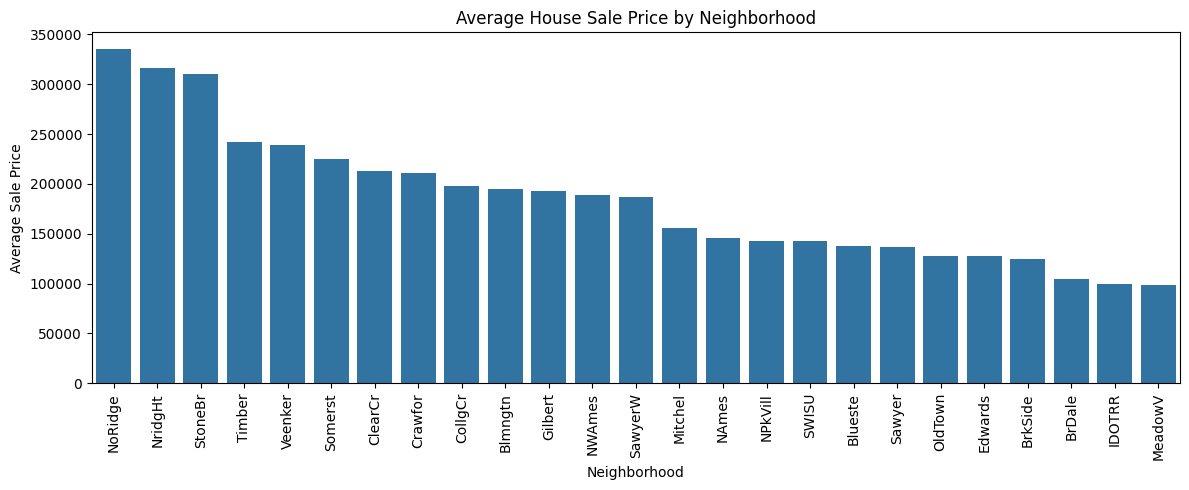

In [60]:
# Avg house price per neighborhood visualization
plt.figure(figsize=(12, 5))

sns.barplot(
    data=neighborhood_prices,
    x="neighborhood",
    y="average_price"
)

plt.title("Average House Sale Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Average Sale Price")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [61]:
# Identify and handle outliers
outlier_columns = ["sale_price", "lot_area", "living_area"]

for col in outlier_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} outliers")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}\n")

sale_price: 61 outliers
Lower bound: 3937.50
Upper bound: 340037.50

lot_area: 69 outliers
Lower bound: 1481.50
Upper bound: 17673.50

living_area: 31 outliers
Lower bound: 158.62
Upper bound: 2747.62



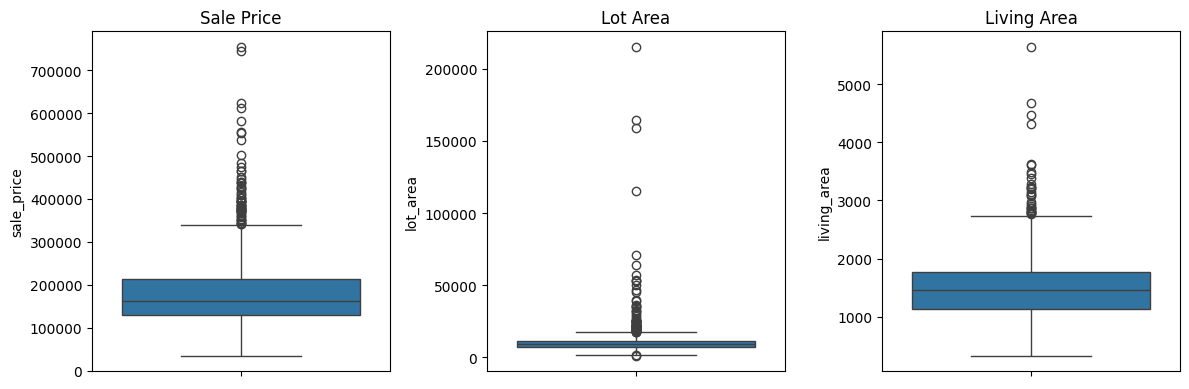

In [62]:
# Visualise the outliers
plt.figure(figsize=(12, 4))

for i, col in enumerate(outlier_columns, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df_clean[col])
    plt.title(col.replace("_", " ").title())

plt.tight_layout()
plt.show()

In [63]:
# Handle outliers by clipping the values
df_final = df_clean.copy()

for col in outlier_columns:
    Q1 = df_final[col].quantile(0.25)
    Q3 = df_final[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_final[col] = df_final[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Dataset shape before outlier handling:", df_clean.shape)
print("Dataset shape after outlier handling:", df_final.shape)

Dataset shape before outlier handling: (1460, 81)
Dataset shape after outlier handling: (1460, 81)


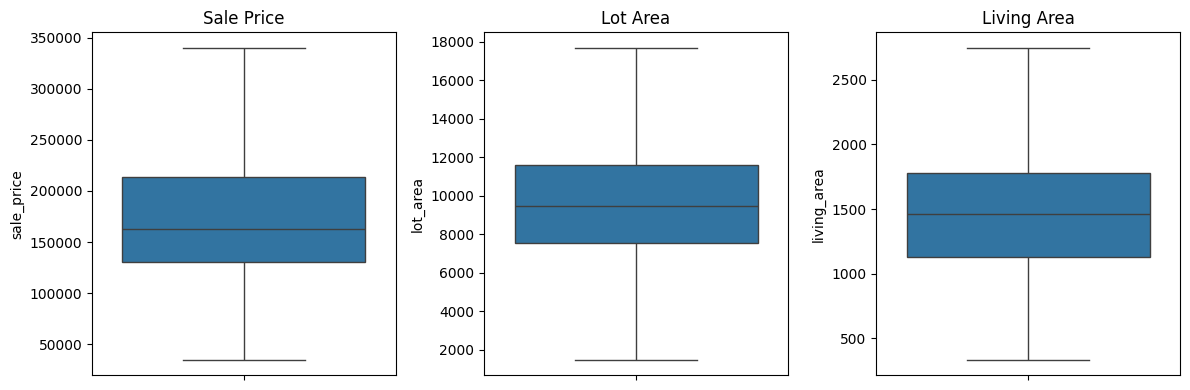

In [64]:
# Visualise the outliers after clipping
plt.figure(figsize=(12, 4))

for i, col in enumerate(outlier_columns, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df_final[col])
    plt.title(col.replace("_", " ").title())

plt.tight_layout()
plt.show()

In [65]:
# Check the final dataset
print("Final dataset shape:", df_final.shape)

print("\nRemaining missing values:",
      df_final.isnull().sum().sum())

print("\nFinal dataset preview:")
display(df_final.head())

print("\nSummary of sale prices:")
display(df_final["sale_price"].describe())

Final dataset shape: (1460, 81)

Remaining missing values: 0

Final dataset preview:


,id,mssubclass,mszoning,lotfrontage,lot_area,street,alley,lotshape,landcontour,utilities,...,poolarea,poolqc,fence,miscfeature,miscval,mosold,year_sold,saletype,salecondition,sale_price
0,1,60,RL,65.0,8450.0,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,2,2008,WD,Normal,208500.0
1,2,20,RL,80.0,9600.0,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,5,2007,WD,Normal,181500.0
2,3,60,RL,68.0,11250.0,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,9,2008,WD,Normal,223500.0
3,4,70,RL,60.0,9550.0,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,2,2006,WD,Abnorml,140000.0
4,5,60,RL,84.0,14260.0,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,12,2008,WD,Normal,250000.0



Summary of sale prices:


count      1460.000000
mean     177331.526370
std       67205.835915
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      340037.500000
Name: sale_price, dtype: float64

In [66]:
# Save the cleaned dataset to a new CSV file
df_final.to_csv("outputs/assignment-08.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.
